In [1]:
#Imports
from astropy.io import fits
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pathlib
from pathlib import Path
from matplotlib.colors import ListedColormap, BoundaryNorm
import os

In [2]:
# for the full path
here = pathlib.Path.cwd() #current working directory
print(here)

C:\Users\AnaAm\ccd_data


In [3]:
dpath_ubai2505m = here / 'hst-calibration/ubai2505m/'
dpath_ubai2507m = here / 'hst-calibration/ubai2507m/'
dpath_ubai2508m = here / 'hst-calibration/ubai2508m/'

In [4]:
def load_calibration_files(dpath):
    """
    Load and map calibration archives rutes to a dictionary.
    """
    dpath = (dpath)
    files = {
        'raw': list(dpath.glob('*_raw.fits'))[0],
        'maskfile': list(dpath.glob('*_maskfile.fits'))[0],
        'blevfile': list(dpath.glob('*_blevfile.fits'))[0],
        'biasfile': list(dpath.glob('*_biasfile.fits'))[0],
        'darkfile': list(dpath.glob('*_darkfile.fits'))[0],
        'flatfile': list(dpath.glob('*_flatfile.fits'))[0],
    }
    return files
            
def read_fits_file(file_path, ext=1):
    """
    Standard function to read FITS files.
    It extracts primary header, extensions and a data header.
    """
    with fits.open(file_path) as hdul:
        primary_header = hdul[0].header
        data = hdul[ext].data
        data_header = hdul[ext].header
    return primary_header, data_header, data

In [5]:
files = load_calibration_files(dpath_ubai2505m)

In [6]:
primary_header, raw_header, raw_data = read_fits_file(files['raw'], ext=1)

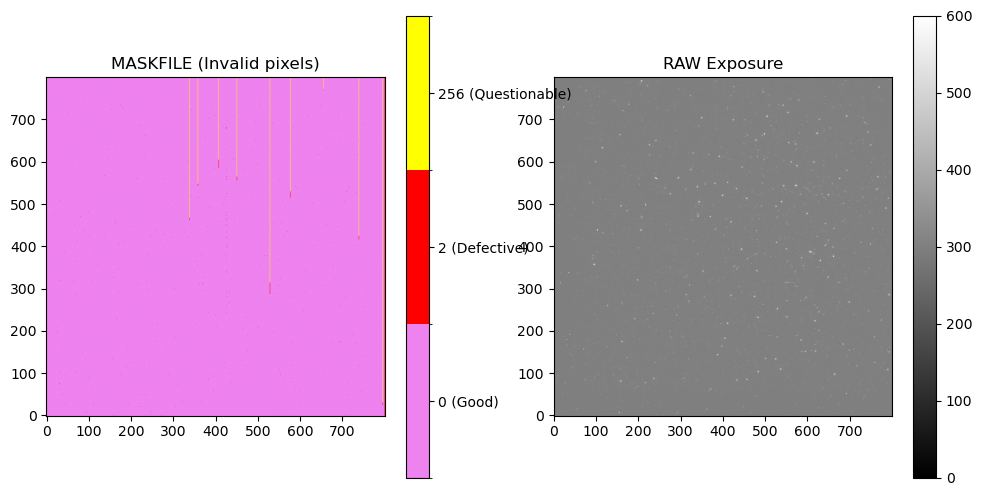

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
_, mask_header, mask_data = read_fits_file(files['maskfile'], ext=0)
# 0 -> 0 (Good), 2 -> 1 (Defective), 256 -> 2 (Questionable)
data_to_plot = np.zeros_like(mask_data[0, :, :], dtype=float)
data_to_plot[mask_data[0, :, :] == 2] = 1
data_to_plot[mask_data[0, :, :] == 256] = 2

cmap = ListedColormap(['violet', 'red', 'yellow'])
bounds = [-0.5, 0.5, 1.5, 2.5]
norm = BoundaryNorm(bounds, cmap.N)

im1 = axes[0].imshow(data_to_plot, cmap=cmap, norm=norm, origin='lower')
axes[0].set_title('MASKFILE (Invalid pixels)')
cbar = fig.colorbar(im1, ax=axes[0], ticks=[0, 1, 2])
cbar.set_ticklabels(['0 (Good)', '2 (Defective)', '256 (Questionable)'])

im2 = axes[1].imshow(raw_data[0, :, :], cmap='gray', origin='lower', vmin= 0, vmax=600)
axes[1].set_title('RAW Exposure')
fig.colorbar(im2, ax=axes[1])

plt.show()

In [8]:
def parse_blev_file(filename, chip=1):
    """
    Parse the BLEVFILE by opening the FITS file securely 
    """
    with fits.open(filename) as hdul:
        # we detect if we are in the special case of 2507m 
        if "ubai2507m" in str(filename):
            data_cube = hdul[0].data
            data = data_cube[chip - 1] if data_cube.ndim == 3 else data_cube
        else:
            try:
                data = hdul[chip].data
            except (IndexError, AttributeError):
                data = hdul[0].data[chip] if hdul[0].data.ndim == 3 else hdul[0].data
    
    # we make sure that it is a valid 2D matrix before slicing the overscan
    if data.ndim != 2:
        if data.ndim == 3:
            data = data[:, :, chip] if data.shape[2] == 4 else data[chip, :, :]
            
    #rows 9 to 790, columns 8 to 14 
    overscan = data[9:790, 8:14]
    
    odd_vals = overscan[:, 0::2]
    even_vals = overscan[:, 1::2]
    
    return np.mean(odd_vals), np.mean(even_vals)
    
def apply_bias_corr(raw_data, blev_data):
    """
    Apply bias level correction by separating odd and even columns 
    according to Python convention.
    """
    mean_odd, mean_even = parse_blev_file(blev_data)
    
    # we create a copy to avoid modifying the original array directly
    corrected_data = raw_data.copy()
    
    #Subtract the corresponding mean for each column 
    corrected_data[:, 0::2] -= mean_odd
    corrected_data[:, 1::2] -= mean_even
    
    return corrected_data
    
def run_calibration(dpath, chip=1):
    #we load the rutes for the files 
    calib_files = load_calibration_files(dpath)
    
    #2507m files has a different structure so we detect if we are working with that file to do another proccess
    is_2507 = "ubai2507m" in str(dpath)
    
    #read raw file
    with fits.open(calib_files['raw']) as hdul:
        if is_2507:
            # For 2507m we use the extension 0
            raw_data = hdul[0].data[chip - 1].astype(float) if hdul[0].data.ndim == 3 else hdul[0].data.astype(float)
            exptime = float(hdul[0].header.get('EXPTIME', 1.0))
        else:
            # For 2505m and 2508m 
            raw_data = hdul[1].data.astype(float)
            exptime = float(hdul[1].header.get('EXPTIME', 1.0))
            
    # apply blev and bias corrections
    mean_odd, mean_even = parse_blev_file(calib_files['blevfile'], chip=chip)
    bias_corr = raw_data.copy()
    bias_corr[:, 0::2] -= mean_odd
    bias_corr[:, 1::2] -= mean_even

    #Auxiliar function 
    def get_file_data(filepath):
        with fits.open(filepath) as hdul:
            if is_2507:
                data = hdul[0].data
                return (data[chip - 1] if data.ndim == 3 else data).astype(float)
            else:
                #For the other files
                return hdul[0].data.astype(float)

    # Substract bias
    bias_data = get_file_data(calib_files['biasfile'])
    bias_corr = bias_corr - bias_data
    
    # Substract dark
    dark_data = get_file_data(calib_files['darkfile'])
    dark_corr = bias_corr - (dark_data * exptime)
    
    # Correct flat
    flat_data = get_file_data(calib_files['flatfile'])
    flat_corr = dark_corr * flat_data
    
    # Decide not to apply mask
    mask_data = get_file_data(calib_files['maskfile'])
    #calibrated_image = np.where(mask_data == 0, flat_corr, np.nan) 
    calibrated_image = flat_corr
    #Aprroximating sky value (median) 
    img = calibrated_image[0] if calibrated_image.ndim == 3 else calibrated_image
    sky_background = np.nanmedian(img)
    #sky_background = np.nanmedian(calibrated_image)
    cal_imag_wt_sky = img - sky_background
    
    return calibrated_image, cal_imag_wt_sky

In [9]:
dpath_folder = dpath_ubai2505m
imagen_final, imagen_final_wtsky = run_calibration(dpath_folder)

1HISTORY   below the initial guess image. The first initial guess image          [astropy.io.fits.card]


In [12]:
dpath_folder1 = dpath_ubai2507m
imagen_final1, imagen_final_wtsky1 = run_calibration(dpath_folder1)

In [13]:
dpath_folder2 = dpath_ubai2508m
imagen_final2, imagen_final_wtsky2 = run_calibration(dpath_folder2)

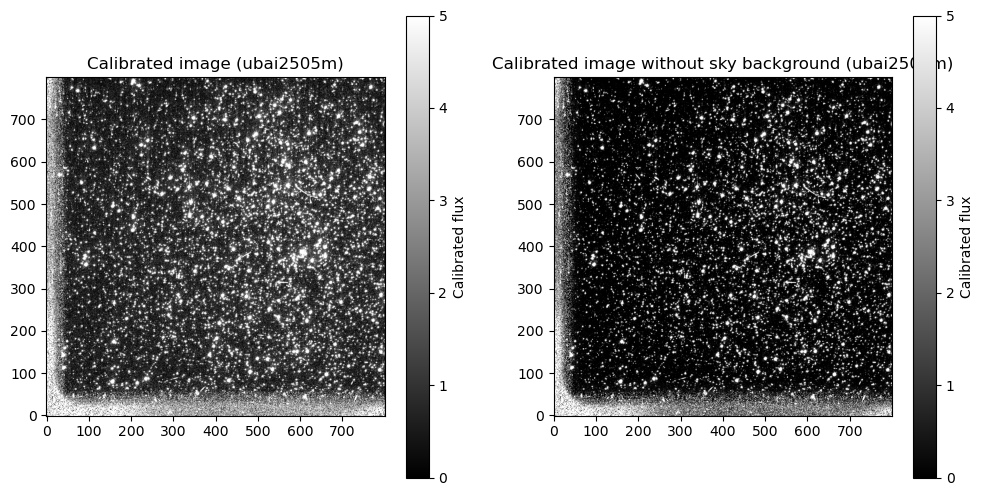

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    
im1 = axes[0].imshow(imagen_final[0], origin='lower', cmap='gray', vmin=0, vmax=5)
axes[0].set_title('Calibrated image (ubai2505m)')
fig.colorbar(im1, ax=axes[0],label='Calibrated flux' )

im2 = axes[1].imshow(imagen_final_wtsky, origin='lower', cmap='gray', vmin=0, vmax=5)
axes[1].set_title('Calibrated image without sky background (ubai2505m)')
fig.colorbar(im2, ax=axes[1], label='Calibrated flux')
plt.show()

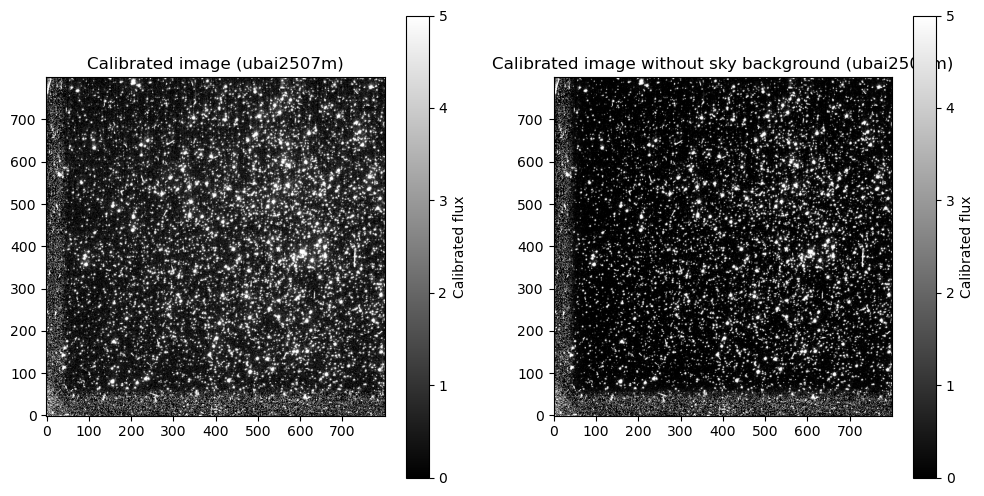

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    
im1 = axes[0].imshow(imagen_final1, origin='lower', cmap='gray', vmin=0, vmax=5)
axes[0].set_title('Calibrated image (ubai2507m)')
fig.colorbar(im1, ax=axes[0],label='Calibrated flux' )

im2 = axes[1].imshow(imagen_final_wtsky1, origin='lower', cmap='gray', vmin=0, vmax=5)
axes[1].set_title('Calibrated image without sky background (ubai2507m)')
fig.colorbar(im2, ax=axes[1], label='Calibrated flux')
plt.show()

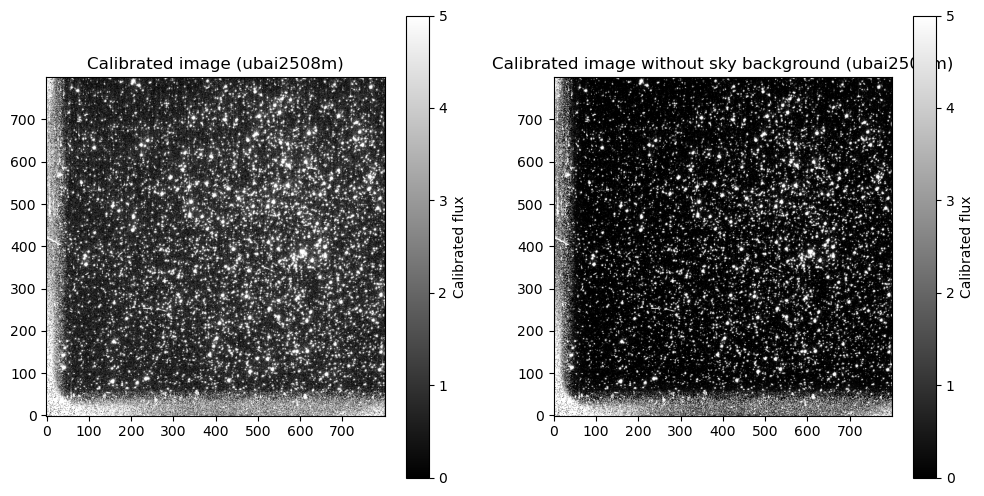

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    
im1 = axes[0].imshow(imagen_final2[0], origin='lower', cmap='gray', vmin=0, vmax=5)
axes[0].set_title('Calibrated image (ubai2508m)')
fig.colorbar(im1, ax=axes[0],label='Calibrated flux' )

im2 = axes[1].imshow(imagen_final_wtsky2, origin='lower', cmap='gray', vmin=0, vmax=5)
axes[1].set_title('Calibrated image without sky background (ubai2508m)')
fig.colorbar(im2, ax=axes[1], label='Calibrated flux')
plt.show()

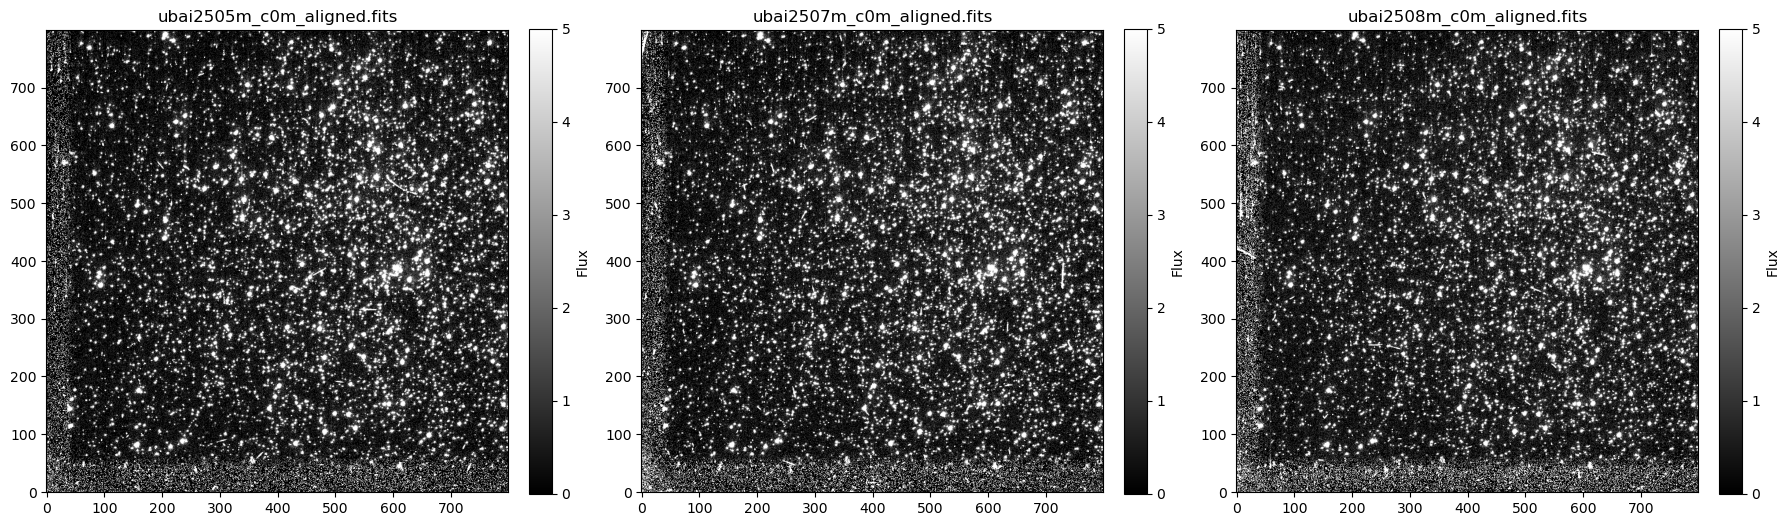

In [4]:
#Visualising aligned files 
aligned_dir = here 
files_to_compare = [
    aligned_dir / 'F336W/ubai2505m_c0m_aligned.fits',
    aligned_dir / 'F336W/ubai2507m_c0m_aligned.fits',
    aligned_dir / 'F336W/ubai2508m_c0m_aligned.fits'
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, file_path in enumerate(files_to_compare):
    with fits.open(file_path) as hdul:
        data = hdul[0].data if (hdul[0].data is not None and hdul[0].data.ndim >= 2) else hdul[1].data
        if data.ndim == 3:
            img_data = data[:, :, 1] if data.shape[2] == 4 else data[1, :, :]
        else:
            img_data = data

    im = axes[i].imshow(img_data, origin='lower', cmap='gray', vmin=0, vmax=5)
    axes[i].set_title(file_path.name)
    fig.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04, label='Flux')

plt.tight_layout()
plt.show()

In [21]:
#PHOTOMETRY

In [5]:
arch_html = here / 'Photometry_Tables.html'
tabs = pd.read_html(str(arch_html))

df_f336w = tabs[0]
print(df_f336w)

#To extract specefic values as floats:
photflam_f336w = float(df_f336w.loc[df_f336w['Keyword'] == 'PHOTFLAM', 'Value'].values[0])
photzpt_f336w = float(df_f336w.loc[df_f336w['Keyword'] == 'PHOTZPT', 'Value'].values[0])
zp_corr_f336w = float(df_f336w.loc[df_f336w['Keyword'] == 'ZP_CORR', 'Value'].values[0])

print("PHOTFLAM:", photflam_f336w)
print("PHOTZPT:", photzpt_f336w)
print("ZP_CORR:", zp_corr_f336w)

    Keyword                       Value  \
0  PHOTMODE  'WFPC2,1,A2D15,F336W,,CAL'   
1  PHOTFLAM                1.115396E-16   
2   PHOTZPT                       -21.1   
3  PHOTPLAM                    3359.474   
4    PHOTBW                    204.4908   
5   ZP_CORR                 -0.03288031   

                                    Description  
0                        Photometry mode string  
1                           Inverse Sensitivity  
2                                    Zero point  
3                              Pivot wavelength  
4                   RMS bandwidth of the filter  
5  Delta magnitude correction for contamination  
PHOTFLAM: 1.115396e-16
PHOTZPT: -21.1
ZP_CORR: -0.03288031


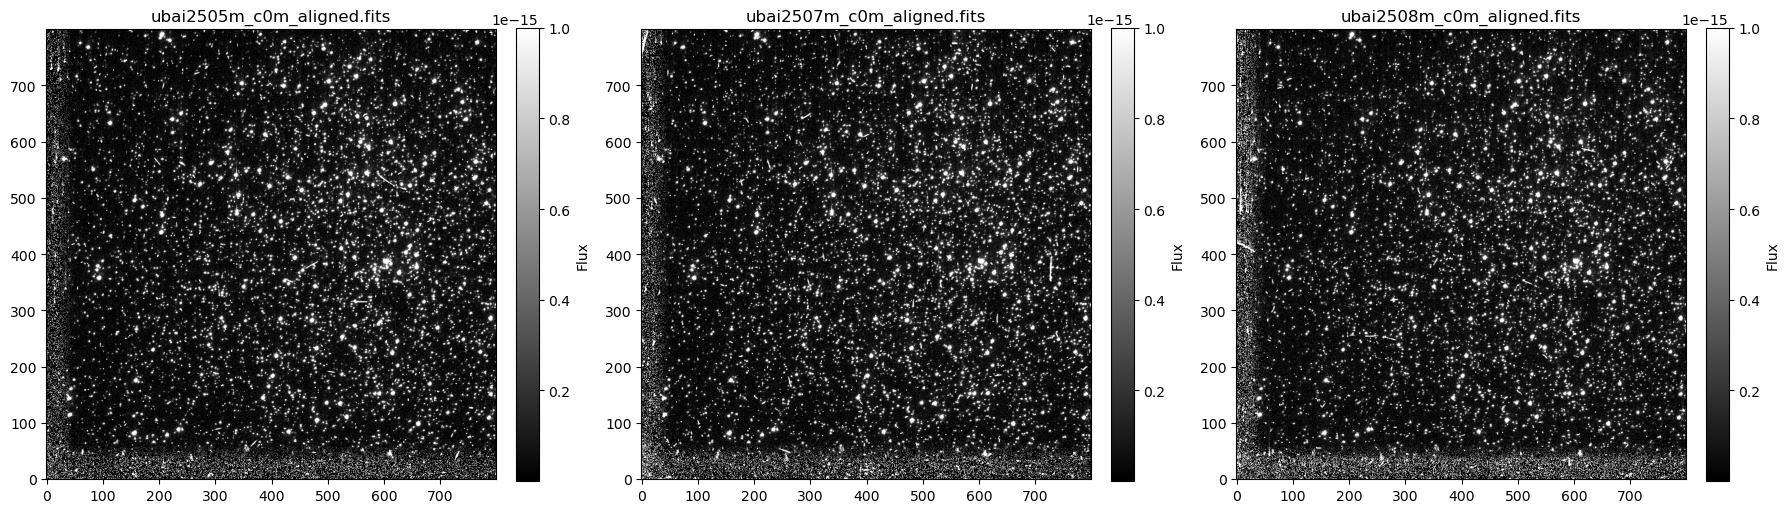

In [6]:
#Applying photometry to aligned fits 
aligned_dir = here 
files_to_compare = [
    aligned_dir / 'F336W/ubai2505m_c0m_aligned.fits',
    aligned_dir / 'F336W/ubai2507m_c0m_aligned.fits',
    aligned_dir / 'F336W/ubai2508m_c0m_aligned.fits'
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, file_path in enumerate(files_to_compare):
    with fits.open(file_path) as hdul:
        data = hdul[0].data if (hdul[0].data is not None and hdul[0].data.ndim >= 2) else hdul[1].data  
        if data.ndim == 3:
            img_data = data[:, :, 1] if data.shape[2] == 4 else data[1, :, :]
            img_data = img_data * photflam_f336w
        else:
            img_data = data
            img_data = img_data * photflam_f336w

    im = axes[i].imshow(img_data, origin='lower', cmap='gray', vmin = 1e-20, vmax= 1e-15)
    axes[i].set_title(file_path.name)
    fig.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04, label='Flux')

plt.tight_layout()
plt.show()

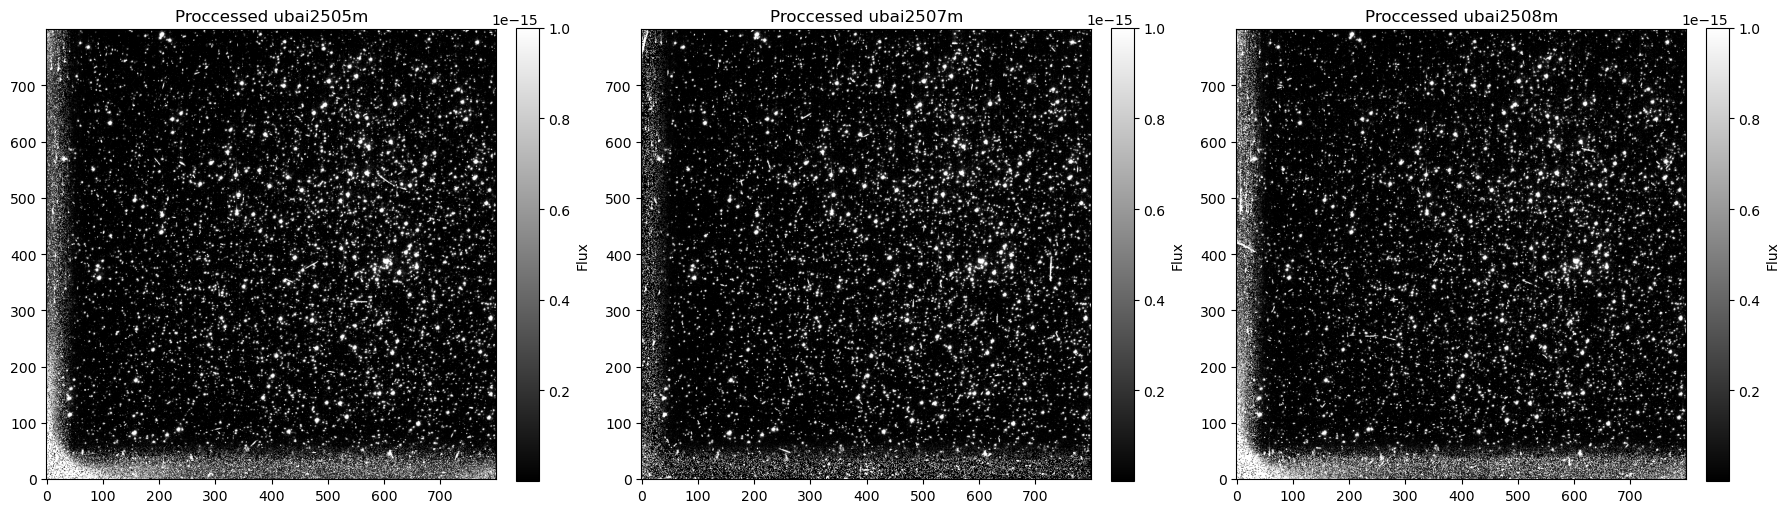

In [22]:
#Apply photometry to calibrated images 
plt.close('all')
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

count = imagen_final_wtsky
g = count * photflam_f336w
count1 = imagen_final_wtsky1
g1 = count1 * photflam_f336w
count2 = imagen_final_wtsky2
g2 = count2 * photflam_f336w

im0 = axes[0].imshow(g,  origin='lower', cmap='gray', vmin=1e-20, vmax=1e-15)
im1 = axes[1].imshow(g1, origin='lower', cmap='gray', vmin=1e-20, vmax=1e-15)
im2 = axes[2].imshow(g2, origin='lower', cmap='gray', vmin=1e-20, vmax=1e-15)

axes[0].set_title('Proccessed ubai2505m')
axes[1].set_title('Proccessed ubai2507m')
axes[2].set_title('Proccessed ubai2508m')
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label='Flux')
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04, label='Flux')
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04, label='Flux')


plt.tight_layout()
plt.show()


In [23]:
#COMPARE AND CONTRAST 
#Original aligned data
aligned_dir = here 
files_to_compare = [
    aligned_dir / 'F336W/ubai2505m_c0m_aligned.fits',
    aligned_dir / 'F336W/ubai2507m_c0m_aligned.fits',
    aligned_dir / 'F336W/ubai2508m_c0m_aligned.fits'
]

#Processed data
processed_list = [
    imagen_final_wtsky * photflam_f336w if imagen_final_wtsky.ndim == 3 else imagen_final_wtsky * photflam_f336w,
    imagen_final_wtsky1 * photflam_f336w if imagen_final_wtsky1.ndim == 3 else imagen_final_wtsky1 *photflam_f336w,
    imagen_final_wtsky2 * photflam_f336w if imagen_final_wtsky2.ndim == 3 else imagen_final_wtsky2 * photflam_f336w
]

nombres_etapas = ["Exposure 2505m", "Exposure 2507m", "Exposure 2508m"]
comp_results = []

for i, file_path in enumerate(files_to_compare):
  
    with fits.open(file_path) as hdul:
        data = hdul[0].data if (hdul[0].data is not None and hdul[0].data.ndim >= 2) else hdul[1].data
        if data.ndim == 3:
            img_aligned = data[:, :, 1] if data.shape[2] == 4 else data[1, :, :]
            img_aligned = img_aligned * photflam_f336w
        else:
            img_aligned = data
            img_aligned = img_aligned * photflam_f336w

    img_processed = processed_list[i]
    valid_mask = np.isfinite(img_aligned) & np.isfinite(img_processed)
    arr_orig = img_aligned[valid_mask]
    arr_proc = img_processed[valid_mask]
    
    # Linear correlation between aligned and proccessed images 
    correlacion = np.corrcoef(arr_orig, arr_proc)[0, 1] if len(arr_orig) > 1 else 0.0
    
    comp_results.append({
        'Exposure': nombres_etapas[i],
        'Original mean': (np.mean(arr_orig)),
        'Processed mean': (np.mean(arr_proc)),
        'Correlation': (correlacion)
    })

df_astro_comp = pd.DataFrame(comp_results)
print(df_astro_comp)

         Exposure  Original mean  Processed mean  Correlation
0  Exposure 2505m   2.576001e-16    2.607753e-16     0.881279
1  Exposure 2507m   3.654372e-16    2.792231e-16     0.999996
2  Exposure 2508m   4.923121e-16    4.794368e-16     0.997342


In [24]:
aligned = fits.getdata(files_to_compare[1]) * photflam_f336w # ubai2507m aligned
procesada = processed_list[1] 
print(aligned.shape, procesada.shape)
stars = [(600, 390)] # lista de pares (x, y)

(800, 800) (800, 800)


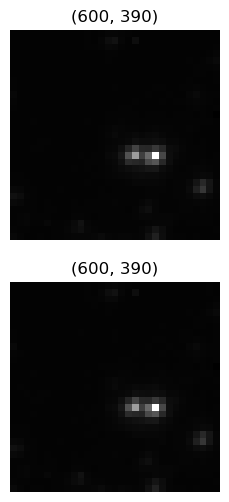

In [25]:
fig, axes = plt.subplots(2, len(stars), figsize=(3*len(stars), 6), squeeze=False)
for j, (x, y) in enumerate(stars):
    for i, im in enumerate([aligned, procesada]):
        axes[i, j].imshow(im[y-15:y+16, x-15:x+16], origin='lower', cmap='gray')
        axes[i, j].set_title(f'({x}, {y})')
        axes[i, j].axis('off')
plt.show()

In [26]:
sub = aligned[375:406, 585:616]
dy, dx = np.unravel_index(np.nanargmax(sub), sub.shape)
x_pk, y_pk = 585 + dx, 375 + dy
print(x_pk, y_pk)

606 387


In [27]:
stars = [(int(x_pk), int(y_pk))] 

In [28]:
def star_flux(img, x, y, r=4, r_in=8, r_out=12):
    h = r_out + 1
    stamp = img[y-h:y+h+1, x-h:x+h+1]
    yy, xx = np.indices(stamp.shape)
    d = np.hypot(xx - h, yy - h)
    bkg = np.nanmedian(stamp[(d >= r_in) & (d <= r_out)]) # cielo local
    return np.nansum(stamp[d <= r] - bkg) # flujo de la estrella

In [29]:
def flux_to_mag(flux):
    """
    convert a flux to an apparent magnitude using the
    data header [PHOTZPT]
    """
    mag = -2.5 * np.log10(flux) -21.1
    return mag

def get_abs_mag(dpc, app_mag):
    """
    convert an apparent magnitude to absolute magnitude
    given a distance in parsecs(pc)
    """
    return app_mag +5 -5*np.log10(dpc)
    

In [30]:
flux_aligned = np.array([star_flux(aligned, x, y) for x, y in stars])
flux_proc = np.array([star_flux(procesada, x, y) for x, y in stars])

app_mags_al = flux_to_mag(flux_aligned)
app_mags_pr = flux_to_mag(flux_proc)
abs_mags_pr = get_abs_mag(16.4e3, app_mags_pr)

for (x, y), f, a, b in zip(stars, flux_proc, app_mags_pr, abs_mags_pr):
    print(f"({x:4d},{y:4d}) Flux: {f:0.2e}\t erg/cm^2/s/A \t m_app:{a:0.2f}\t M_abs:{b:0.2f}")

( 606, 387) Flux: 4.39e-13	 erg/cm^2/s/A 	 m_app:9.79	 M_abs:-6.28


In [31]:
df_mags = pd.DataFrame({
    'x': [s[0] for s in stars], 'y': [s[1] for s in stars],
    'm_aligned': app_mags_al, 'm_procesada': app_mags_pr,
})
df_mags['dm'] = df_mags.m_procesada - df_mags.m_aligned
print(df_mags.round(3))
print('Δm medio:', round(df_mags.dm.mean(), 3))

     x    y  m_aligned  m_procesada     dm
0  606  387      9.791        9.793  0.002
Δm medio: 0.002


## Compare and Contrast

To validate the calibration pipeline, each calibrated exposure (bias level
subtraction, bias, dark and flat-field correction, and sky subtraction) was
compared against the science-ready `*_c0m_aligned.fits` files, after converting
both to physical flux units with PHOTFLAM.

Visually, the three calibrated frames reproduce the same
stellar field as their aligned counterparts: the same stars, the same cosmic-ray
tracks, and the same noisy strips along the left and bottom edges. Quantitatively, the
correlation is very high: 0.999996 for ubai2507m, 0.9973 for ubai2508m and
0.881 for ubai2505m. The mean flux also agrees well for ubai2505m
(2.608e-16 vs 2.576e-16 erg/cm²/s/Å, about 1%) and ubai2508m (4.794e-16 vs
4.923e-16, about 3%). This indicates that the calibration steps are applied
correctly and that the pipeline is consistent across exposures, including
ubai2507m, whose files have a different structure (data stored in extension 0,
with the chips in a data cube).

The lower correlation of ubai2505m (0.881) is not accompanied
by any visible calibration artifact. Since correlation is very sensitive to
sub-pixel misalignments in crowded fields of point sources, it is most likely
due to the shift/resampling applied when aligning the image.
The mean flux of ubai2507m is about 24% lower in our processed image
(2.792e-16 vs 3.654e-16). Because its correlation is almost exactly 1, the
difference is a constant offset or scale factor rather than a structural one,
and it is probably related to the background estimate (our pipeline subtracts
the median of the chip, whereas the provided files may use a different sky
level). 

As an additional test, aperture photometry was performed at the same position,
(x, y) = (606, 387), in the aligned and in the processed ubai2507m images, and
the fluxes were converted to magnitudes with
m = -2.5 log10(F_λ) + PHOTZPT (PHOTZPT = -21.1). We obtained
m = 9.791 for the aligned image and m = 9.793 for ours, a difference of
0.002 mag, which confirms that the flux scale of our calibrated image is
consistent with the provided science-ready file.

The pipeline does not apply the mask file,
does not correct for cosmic rays, and the sky background is a single median of
the chip rather than a local estimate; these choices may contribute to the small
residual differences with respect to the provided products. The photometric
check uses one bright object that is a close pair of peaks. The
same procedure was applied to both images, so the magnitude difference between
them is not affected by these choices.

In [32]:
def save_processed(calibrated, wtsky, name, outdir, chip_idx=0):
    """Save the processsed images as 2D fits in processed folder"""
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True) 

    cal = calibrated[chip_idx] if calibrated.ndim == 3 else calibrated
    img = wtsky[chip_idx] if wtsky.ndim == 3 else wtsky
    sky = float(np.nanmedian(cal - img)) # cielo que se restó

    hdr = fits.Header()
    hdr['SRCFILE'] = (name, 'exposure root name')
    hdr['CHIPIDX'] = (chip_idx, '0-based chip index in the cube')
    hdr['BUNIT'] = ('DN', 'units of the image data')
    hdr['SKYSUB'] = (sky, 'sky value subtracted (median, DN)')
    hdr['HISTORY'] = 'Calibrated: blev, bias, dark, flat; sky subtracted'

    out = outdir / f'{name}_processed_wtsky.fits'
    fits.PrimaryHDU(data=img.astype(np.float32), header=hdr).writeto(out, overwrite=True)
    return out

outdir = here / 'hst-processed'
paths = [
    save_processed(imagen_final,  imagen_final_wtsky,  'ubai2505m', outdir),
    save_processed(imagen_final1, imagen_final_wtsky1, 'ubai2507m', outdir),
    save_processed(imagen_final2, imagen_final_wtsky2, 'ubai2508m', outdir),
]
print(paths)

[WindowsPath('C:/Users/AnaAm/ccd_data/hst-processed/ubai2505m_processed_wtsky.fits'), WindowsPath('C:/Users/AnaAm/ccd_data/hst-processed/ubai2507m_processed_wtsky.fits'), WindowsPath('C:/Users/AnaAm/ccd_data/hst-processed/ubai2508m_processed_wtsky.fits')]
